# Lecture 8a: Matrix Formulation of PDE Schemes
## FTCS Diffusion

This notebook goes with the Lecture 8a slides. The slides derive the matrix formulation step by step; here we **check it and explore it in code**.

**A note on notation.** The slides use the FTCS coefficient $\kappa\tau/h^2$. The functions below take `tau_rel` $= \tau/t_\sigma$ with $t_\sigma = h^2/(2\kappa)$, so

$$\frac{\kappa\tau}{h^2} = \frac{\tau_{\text{rel}}}{2}.$$

The slides' stability limit $\kappa\tau/h^2 \le \tfrac{1}{2}$ is the same as `tau_rel` $\le 1$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
%matplotlib inline

# Set plot parameters for better visualization
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
np.set_printoptions(precision=3, suppress=True, linewidth=120)

---
### Loop version vs matrix version

The same problem as Lecture 6: a delta spike in the middle of a bar with both ends held at $T = 0$. Below are two functions: the loop (slicing) version from Lecture 6 and the matrix version, $\mathbf{T}^{n+1} = \mathbf{A}\,\mathbf{T}^n$.

In [2]:
def diffusion_ftcs(nspace, ntime, tau_rel, args=[1.0, 1.0]):
    """ 
    Compute the solution to the diffusion equation using the 
    forward-time, centered-space (FTCS) algorithm
    
    Parameters:
    -----------
    nspace : int
        Number of spatial grid points
    ntime : int
        Number of time steps
    tau_rel : float
        Time step in units of t_sigma = h²/κ
    args : list
        [L, kappa] where L is domain length and kappa is diffusion coefficient
        
    Returns:
    --------
    tt : ndarray (nspace × ntime)
        Temperature T(x,t) at all grid points and times
    """
    # Check stability condition
    if tau_rel < 1.0:
        print('Solution is expected to be STABLE')
    else:
        print('WARNING: Solution is expected to be UNSTABLE')
        
    L = args[0]              # System extends from x = -L/2 to x = L/2
    kappa = args[1]          # Diffusion coefficient
    h = L / (nspace - 1)     # Grid spacing
    t_sigma = h**2 / (2 * kappa)  # Critical time scale
    tau = tau_rel * t_sigma       # Actual time step
    coeff = kappa * tau / h**2    # FTCS coefficient

    # Set initial and boundary conditions
    tt = np.zeros((nspace, ntime))    # Initialize temperature to zero
    tt[int(nspace/2), 0] = 1.0 / h    # Initial condition: delta function at center
    # Boundary conditions: tt[0, :] = tt[N-1, :] = 0 (implicitly zero)

    # MAIN LOOP: Time stepping
    for istep in range(1, ntime):
        # Compute new temperature using FTCS scheme
        # T_i^(n+1) = T_i^n + coeff * (T_(i+1)^n + T_(i-1)^n - 2*T_i^n)
        tt[1:(nspace-1), istep] = (tt[1:(nspace-1), istep-1] + 
            coeff * (tt[2:nspace, istep-1] + tt[0:(nspace-2), istep-1] - 
                     2 * tt[1:(nspace-1), istep-1]))
        
    return tt

In [3]:
def diffusion_ftcs_mtx(nspace, ntime, tau_rel, args=[1.0, 1.0]):
    """ 
    Compute the solution to the diffusion equation using the 
    forward-time, centered-space algorithm in MATRIX FORMULATION
    
    Parameters:
    -----------
    nspace : int
        Number of spatial grid points
    ntime : int
        Number of time steps
    tau_rel : float
        Time step in units of t_sigma = h²/κ
    args : list
        [L, kappa] where L is domain length and kappa is diffusion coefficient
        
    Returns:
    --------
    tt : ndarray (nspace × ntime)
        Temperature T(x,t) at all grid points and times
    """
    # Check stability condition
    if tau_rel < 1.0:
        print('Solution is expected to be STABLE')
    else:
        print('WARNING: Solution is expected to be UNSTABLE')
        
    L = args[0]              # System extends from x = -L/2 to x = L/2
    kappa = args[1]          # Diffusion coefficient
    h = L / (nspace - 1)     # Grid spacing
    t_sigma = h**2 / (2 * kappa)  # Critical time scale
    tau = tau_rel * t_sigma       # Actual time step
    coeff = kappa * tau / h**2    # FTCS coefficient

    # Set initial and boundary conditions
    tt = np.zeros((nspace, ntime))    # Initialize temperature to zero
    tt[int(nspace/2), 0] = 1.0 / h    # Initial condition: delta function at center

    # Construct diffusion matrix D (NM4P p222)
    # Tridiagonal structure: -2 on diagonal, +1 on off-diagonals
    D = -2*np.eye(nspace) + np.eye(nspace, k=1) + np.eye(nspace, k=-1)
    
    # Apply Dirichlet boundary conditions: T[0] = T[N-1] = 0
    D[0] = 0      # First row all zeros
    D[-1] = 0     # Last row all zeros
    
    # Construct the update matrix A = I + coeff*D
    A = np.identity(nspace) + coeff * D
    
    # MAIN LOOP: Time stepping using matrix multiplication
    for istep in range(1, ntime):
        # Matrix formulation: T^(n+1) = A · T^n
        tt[:, istep] = A.dot(tt[:, istep-1])
        
    return tt

In [5]:
# Physical parameters
L = 1.0          # Domain length
kappa = 1.0      # Diffusion coefficient
nspace = 61      # Number of spatial points
ntime = 300      # Number of time steps

# Compute grid spacing
h = L / (nspace - 1)
print(f"Grid spacing: h = {h:.6f}")

# Compute characteristic time scale
t_sigma = h**2 / (2 * kappa)
print(f"Characteristic time: t_σ = {t_sigma:.6f}")

# Choose time step (must be < t_sigma for stability)
tau = 1e-4
tau_rel = tau / t_sigma
print(f"Relative time step: τ/t_σ = {tau_rel:.6f}")
print(f"Stability check: τ_rel < 1.0? {tau_rel < 1.0}")
print(f"FTCS coefficient: kappa*tau/h^2 = {kappa*tau/h**2:.4f}")

Grid spacing: h = 0.016667
Characteristic time: t_σ = 0.000139
Relative time step: τ/t_σ = 0.720000
Stability check: τ_rel < 1.0? True
FTCS coefficient: kappa*tau/h^2 = 0.3600


In [6]:
print("\n" + "="*60)
print("Running EXPLICIT FTCS (loop-based)...")
print("="*60)
tt = diffusion_ftcs(nspace, ntime, tau_rel, args=[L, kappa])

print("\n" + "="*60)
print("Running MATRIX FORMULATION...")
print("="*60)
tt_mtx = diffusion_ftcs_mtx(nspace, ntime, tau_rel, args=[L, kappa])

# Create spatial and temporal grids for plotting
xplot = np.arange(nspace) * h - 0.5
tplot = np.arange(ntime) * tau


Running EXPLICIT FTCS (loop-based)...
Solution is expected to be STABLE

Running MATRIX FORMULATION...
Solution is expected to be STABLE


In [ ]:
# Compute differences
diff_sum = (tt - tt_mtx).sum()
diff_abs_sum = np.abs(tt - tt_mtx).sum()
diff_max = np.abs(tt - tt_mtx).max()

print("\n" + "="*60)
print("VERIFICATION: Comparing Explicit vs Matrix Methods")
print("="*60)
print(f"Sum of differences:              {diff_sum:.2e}")
print(f"Sum of absolute differences:     {diff_abs_sum:.2e}")
print(f"Maximum absolute difference:     {diff_max:.2e}")
print("\nMethods agree to numerical precision!" if diff_max < 1e-10 else "Significant difference found!")


VERIFICATION: Comparing Explicit vs Matrix Methods
Sum of differences:              5.06e-12
Sum of absolute differences:     5.20e-12
Maximum absolute difference:     3.55e-15

Methods agree to numerical precision!


In [9]:
def doplot(xplot, tplot, tt, ptype):
    fig = plt.figure()
    if ptype == 'mesh':
        ax = fig.add_subplot(projection='3d')
        Tp, Xp = np.meshgrid(tplot, xplot)
        ax.plot_surface(Tp, Xp, tt, rstride=2, cstride=2, cmap=cm.gray)
        ax.set_xlabel('Time')
        ax.set_ylabel('x')
        ax.set_zlabel('T(x,t)')
        ax.set_title('Diffusion of a delta spike')
    elif ptype == 'contour':
        levels = np.linspace(0., 5., num=21) 
        ct = plt.contour(tplot, xplot, tt, levels) 
        plt.clabel(ct, fmt='%1.2f') 
        plt.xlabel('Time')
        plt.ylabel('x')
        plt.title('Temperature contour plot')      
    plt.show()
    return

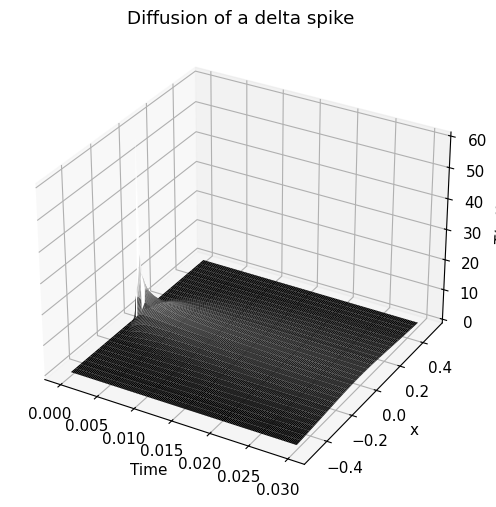

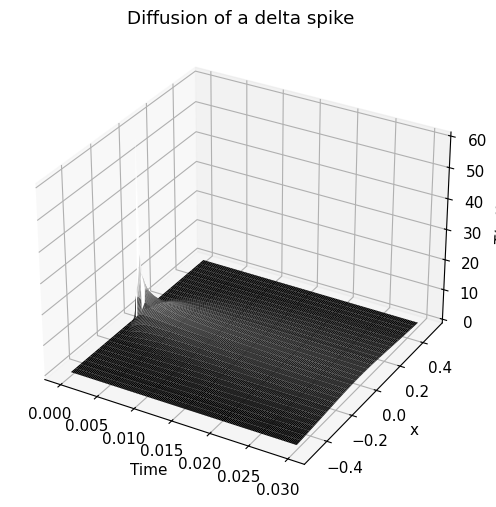

In [10]:
doplot(xplot,tplot, tt, 'mesh')
doplot(xplot,tplot, tt_mtx, 'mesh')

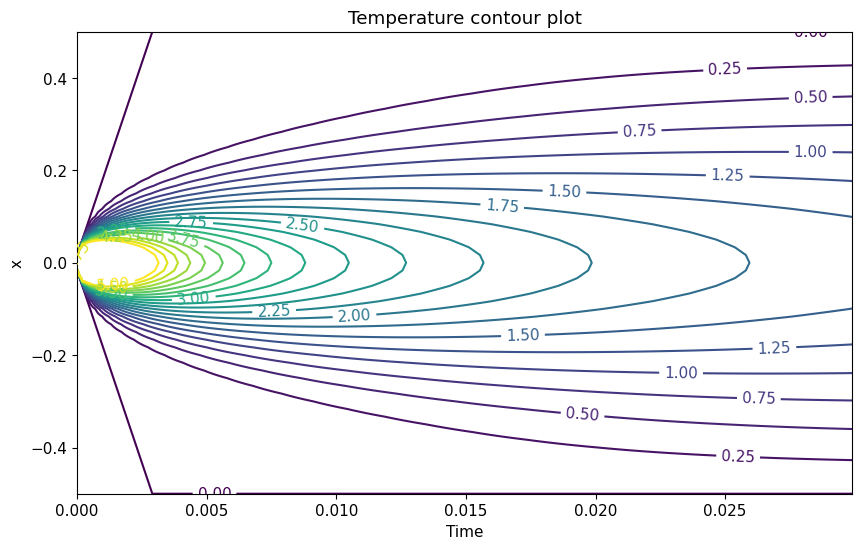

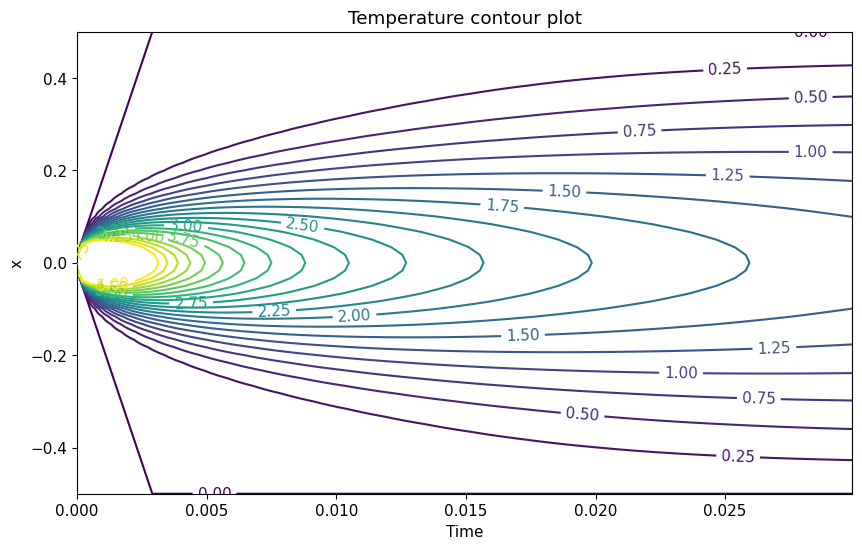

In [11]:
doplot(xplot,tplot, tt, 'contour')
doplot(xplot,tplot, tt_mtx, 'contour')